# Market Map (Sector Treemap Heatmap)

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

A treemap where each rectangle is a stock, sized by market capitalisation, grouped by sector and colored by the day's return. It answers two questions at once: what moved, and how much of the market it represents.

## When to use

- Give a one-glance summary of the market or a portfolio on a given day or period
- Show whether a move is broad (whole sectors one color) or concentrated in a few large names
- Show many holdings (30–500) where size and return both matter

## Avoid when

- Precise comparison of returns is needed (use a sorted bar chart)
- Constituents are similar in size (the treemap adds nothing over a grid heatmap)
- Using a red/green scale alone (≈8% of men cannot separate them); use a blue/orange diverging scale

## Alternatives

- Sorted bar chart of returns
- Highlight table
- Sector bar chart of contributions

## Design tips

- Use a diverging scale with a neutral gray at 0% and clip the extremes so one outlier doesn't wash out the rest
- Draw sector borders thicker than stock borders so the hierarchy is visible
- Label only tiles big enough to hold the text; the rest are available on hover in interactive versions

## Example

31 fictional large-cap stocks in six sectors with simulated market caps and one day's returns (illustrative).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import squarify
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

### Data

In [2]:
rng = np.random.default_rng(8)
sectors = {
    "Technology": ["AAPX", "MSFX", "NVDX", "AVGX", "ORCX", "CRMX", "ADBX"],
    "Financials": ["JPMX", "BACX", "WFCX", "GSX", "MSX"],
    "Health care": ["LLYX", "UNHX", "JNJX", "MRKX", "ABBX"],
    "Consumer": ["AMZX", "TSLX", "HDX", "MCDX", "NKEX"],
    "Energy": ["XOMX", "CVXX", "COPX"],
    "Industrials": ["CATX", "GEX", "HONX", "UPSX", "DEX", "LMX"],
}
sector_move = {"Technology": 1.5, "Financials": -0.5, "Health care": 0.3,
               "Consumer": -1.0, "Energy": -2.1, "Industrials": 0.4}
rows = []
for sector, tickers in sectors.items():
    for t in tickers:
        rows.append({"sector": sector, "ticker": t,
                     "mcap_bn": rng.lognormal(5.2, 0.8),
                     "ret_pct": sector_move[sector] + rng.normal(0, 0.8)})
df = pd.DataFrame(rows).round({"mcap_bn": 0, "ret_pct": 2})
df.sort_values("mcap_bn", ascending=False).head()

,sector,ticker,mcap_bn,ret_pct
27,Industrials,HONX,991.0,0.43
18,Consumer,TSLX,630.0,-1.69
20,Consumer,MCDX,469.0,-1.65
4,Technology,ORCX,390.0,2.61
23,Energy,CVXX,364.0,-1.31


### Plot

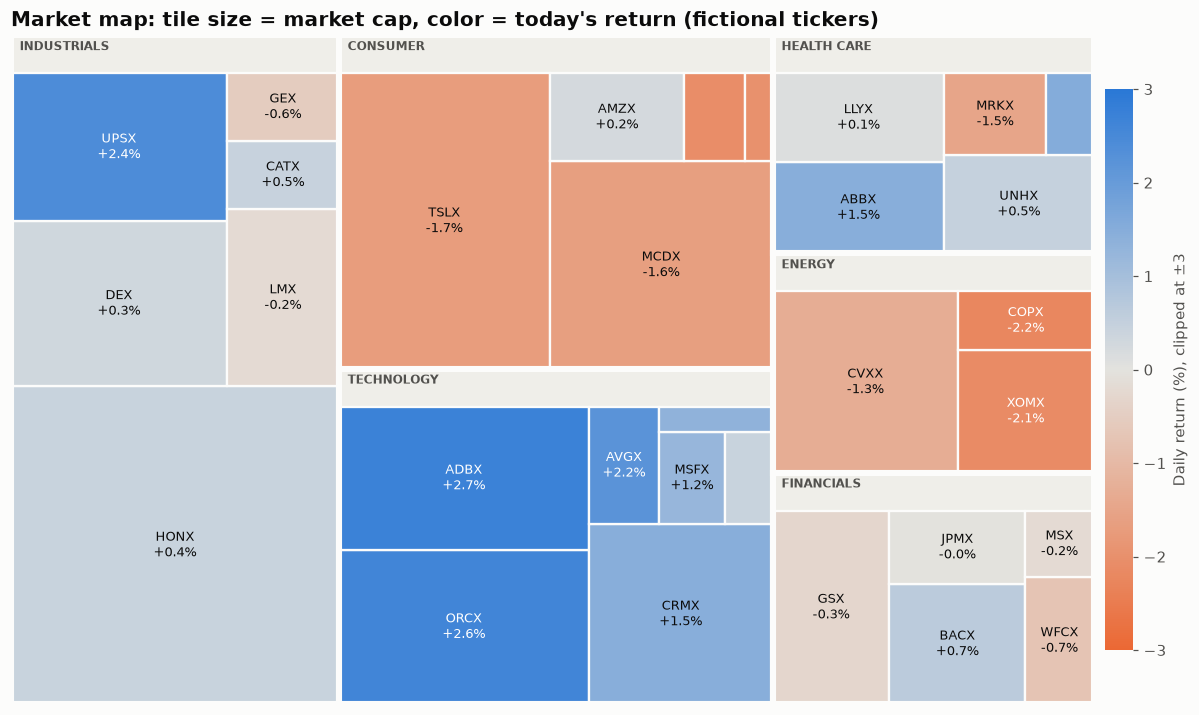

In [3]:
cmap = LinearSegmentedColormap.from_list("loss_gain", [PALETTE[1], "#e3e2de", PALETTE[0]])
norm = TwoSlopeNorm(vmin=-3, vcenter=0, vmax=3)
W, H, header = 100, 60, 3.4

fig, ax = plt.subplots(figsize=(11, 6.6))
by_sector = df.groupby("sector")["mcap_bn"].sum().sort_values(ascending=False)
sector_rects = squarify.squarify(squarify.normalize_sizes(by_sector.values, W, H), 0, 0, W, H)
for sector, r in zip(by_sector.index, sector_rects):
    ax.add_patch(plt.Rectangle((r["x"], r["y"]), r["dx"], r["dy"], facecolor="#efeee9", linewidth=0))
    sub = df[df["sector"] == sector].sort_values("mcap_bn", ascending=False)
    inner_h = r["dy"] - header
    tiles = squarify.squarify(squarify.normalize_sizes(sub["mcap_bn"].values, r["dx"], inner_h),
                              r["x"], r["y"], r["dx"], inner_h)
    for (_, row), q in zip(sub.iterrows(), tiles):
        ax.add_patch(plt.Rectangle((q["x"], q["y"]), q["dx"], q["dy"],
                                   facecolor=cmap(norm(np.clip(row["ret_pct"], -3, 3))),
                                   edgecolor="#fcfcfb", linewidth=1.5))
        if q["dx"] > 6 and q["dy"] > 4.5:
            ink = "white" if abs(row["ret_pct"]) >= 2 else "#0b0b0b"
            ax.text(q["x"] + q["dx"] / 2, q["y"] + q["dy"] / 2,
                    f"{row['ticker']}\n{row['ret_pct']:+.1f}%", ha="center", va="center",
                    fontsize=8.5, color=ink)
    ax.add_patch(plt.Rectangle((r["x"], r["y"]), r["dx"], r["dy"], fill=False,
                               edgecolor="#fcfcfb", linewidth=4))
    ax.text(r["x"] + 0.8, r["y"] + r["dy"] - 0.5, sector.upper(), ha="left", va="top",
            fontsize=8, fontweight="bold", color="#52514e")

ax.set_xlim(0, W)
ax.set_ylim(0, H)
ax.axis("off")
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
cb = fig.colorbar(sm, ax=ax, fraction=0.025, pad=0.01, ticks=[-3, -2, -1, 0, 1, 2, 3])
cb.set_label("Daily return (%), clipped at ±3")
cb.outline.set_visible(False)
ax.set_title("Market map: tile size = market cap, color = today's return (fictional tickers)")
fig.tight_layout()
plt.show()

## How to read it

Big tiles are the largest companies. Blue tiles rose and orange tiles fell; the deeper the color, the bigger the move. Here technology (large and blue) carried the day while energy fell across the board.

---
Standalone script: [`sector_heatmap.py`](sector_heatmap.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)